# 8.2 Laboratorio Comparativo: Regresión vs. Interpolación y Pack GeoGebra (`IDEA-HYB-01`, `HYB-02`)

**Alineación con las presentaciones:** Diapositiva 2 (*"¿Interpolar o ajustar?"*) y Diapositivas 14–15 (*Verificación con GeoGebra y Python*) de **ambas** presentaciones HTML  
**Proyecto:** JobPath (`MineriaProtect`) · Compuerta Final de Gobernanza y Verificación

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().resolve()
for cand in (ROOT, *ROOT.parents):
    if (cand / "data").is_dir() and (cand / "scripts").is_dir():
        ROOT = cand
        break
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts.ScriptsCsv.MetodosNumericos.config import default_config
from scripts.ScriptsCsv.MetodosNumericos.validation import (
    audit_wording_compliance,
    validate_geogebra_scripts,
    verify_figure_manifest,
)

cfg = default_config(ROOT)
tdir, fdir, gdir = cfg.tables_dir, cfg.figures_dir, cfg.geogebra_dir

if not (tdir / "hyb01_loocv_and_extrapolation_matrix.csv").exists():
    from scripts.ScriptsCsv.MetodosNumericos.pipeline import run_all_8_ideas
    run_all_8_ideas(cfg)

## 1. `IDEA-HYB-01` — Laboratorio Empírico Cara a Cara "¿Interpolar o Ajustar?"

Evalúa **4 métodos candidatos** (Regresión Lineal MCO, Lagrange Global Equiespaciado, Lagrange con Nodos Chebyshev y Lagrange Local Cuadrático por Tramos $P_2$) sobre **4 regímenes reales de JobPath** bajo **validación cruzada Leave-One-Out (LOOCV)** y **extrapolación controlada de +2 pasos**.

In [2]:
print("Matriz de benchmark 4 x 4 (métodos vs. regímenes):")
display(pd.read_csv(tdir / "hyb01_loocv_and_extrapolation_matrix.csv"))

print("\nRúbrica ejecutiva de selección de método:")
display(pd.read_csv(tdir / "hyb01_method_selection_rubric.csv"))

Matriz de benchmark 4 x 4 (métodos vs. regímenes):


,regime_name,n_train_nodes,ols_r2,method,loocv_mae,loocv_rmse,loocv_max_err,extrap_2step_mae,loocv_rank,extrap_rank
0,1. Smooth Near-Linear · Career Steps mean_skil...,10,0.995498,OLS Linear Regression,0.041091,0.055822,0.127840,0.074520,1,1
1,1. Smooth Near-Linear · Career Steps mean_skil...,10,0.995498,Piecewise Local Lagrange (P2),0.062745,0.088766,0.157128,0.434136,2,2
2,1. Smooth Near-Linear · Career Steps mean_skil...,10,0.995498,Chebyshev-Node Lagrange,0.086525,0.106086,0.213999,19.547576,3,3
3,1. Smooth Near-Linear · Career Steps mean_skil...,10,0.995498,Global Lagrange (Equispaced),0.201930,0.293668,0.565405,71.282153,4,4
4,2. Noisy Macro Series · Annual mean_skills(year),18,0.899492,Piecewise Local Lagrange (P2),0.087301,0.113939,0.288505,0.171110,1,2
5,2. Noisy Macro Series · Annual mean_skills(year),18,0.899492,Chebyshev-Node Lagrange,0.106995,0.145614,0.320682,0.102260,2,1
6,2. Noisy Macro Series · Annual mean_skills(year),18,0.899492,OLS Linear Regression,0.207300,0.239575,0.417693,0.928458,3,3
7,2. Noisy Macro Series · Annual mean_skills(year),18,0.899492,Global Lagrange (Equispaced),6.393589,12.323899,34.424881,386.360259,4,4
8,3. Steep Nonlinear Monotone · Survival Curve S(q),36,0.693479,Chebyshev-Node Lagrange,0.028397,0.049027,0.168752,0.340426,1,3
9,3. Steep Nonlinear Monotone · Survival Curve S(q),36,0.693479,Piecewise Local Lagrange (P2),0.027472,0.052421,0.199000,0.005988,2,1



Rúbrica ejecutiva de selección de método:


,regime_name,ols_r2,best_in_range_method,best_loocv_rmse,best_extrapolation_method,best_extrap_mae,worst_in_range_method,worst_loocv_rmse
0,1. Smooth Near-Linear · Career Steps mean_skil...,0.995498,OLS Linear Regression,0.055822,OLS Linear Regression,0.074520,Global Lagrange (Equispaced),0.293668
1,2. Noisy Macro Series · Annual mean_skills(year),0.899492,Piecewise Local Lagrange (P2),0.113939,Chebyshev-Node Lagrange,0.102260,Global Lagrange (Equispaced),12.323899
2,3. Steep Nonlinear Monotone · Survival Curve S(q),0.693479,Chebyshev-Node Lagrange,0.049027,Piecewise Local Lagrange (P2),0.005988,Global Lagrange (Equispaced),0.377662
3,4. Exact Concave Table · PCA CumVar V(k) (Ver. B),0.796356,Global Lagrange (Equispaced),0.003645,Piecewise Local Lagrange (P2),0.006756,OLS Linear Regression,0.076465


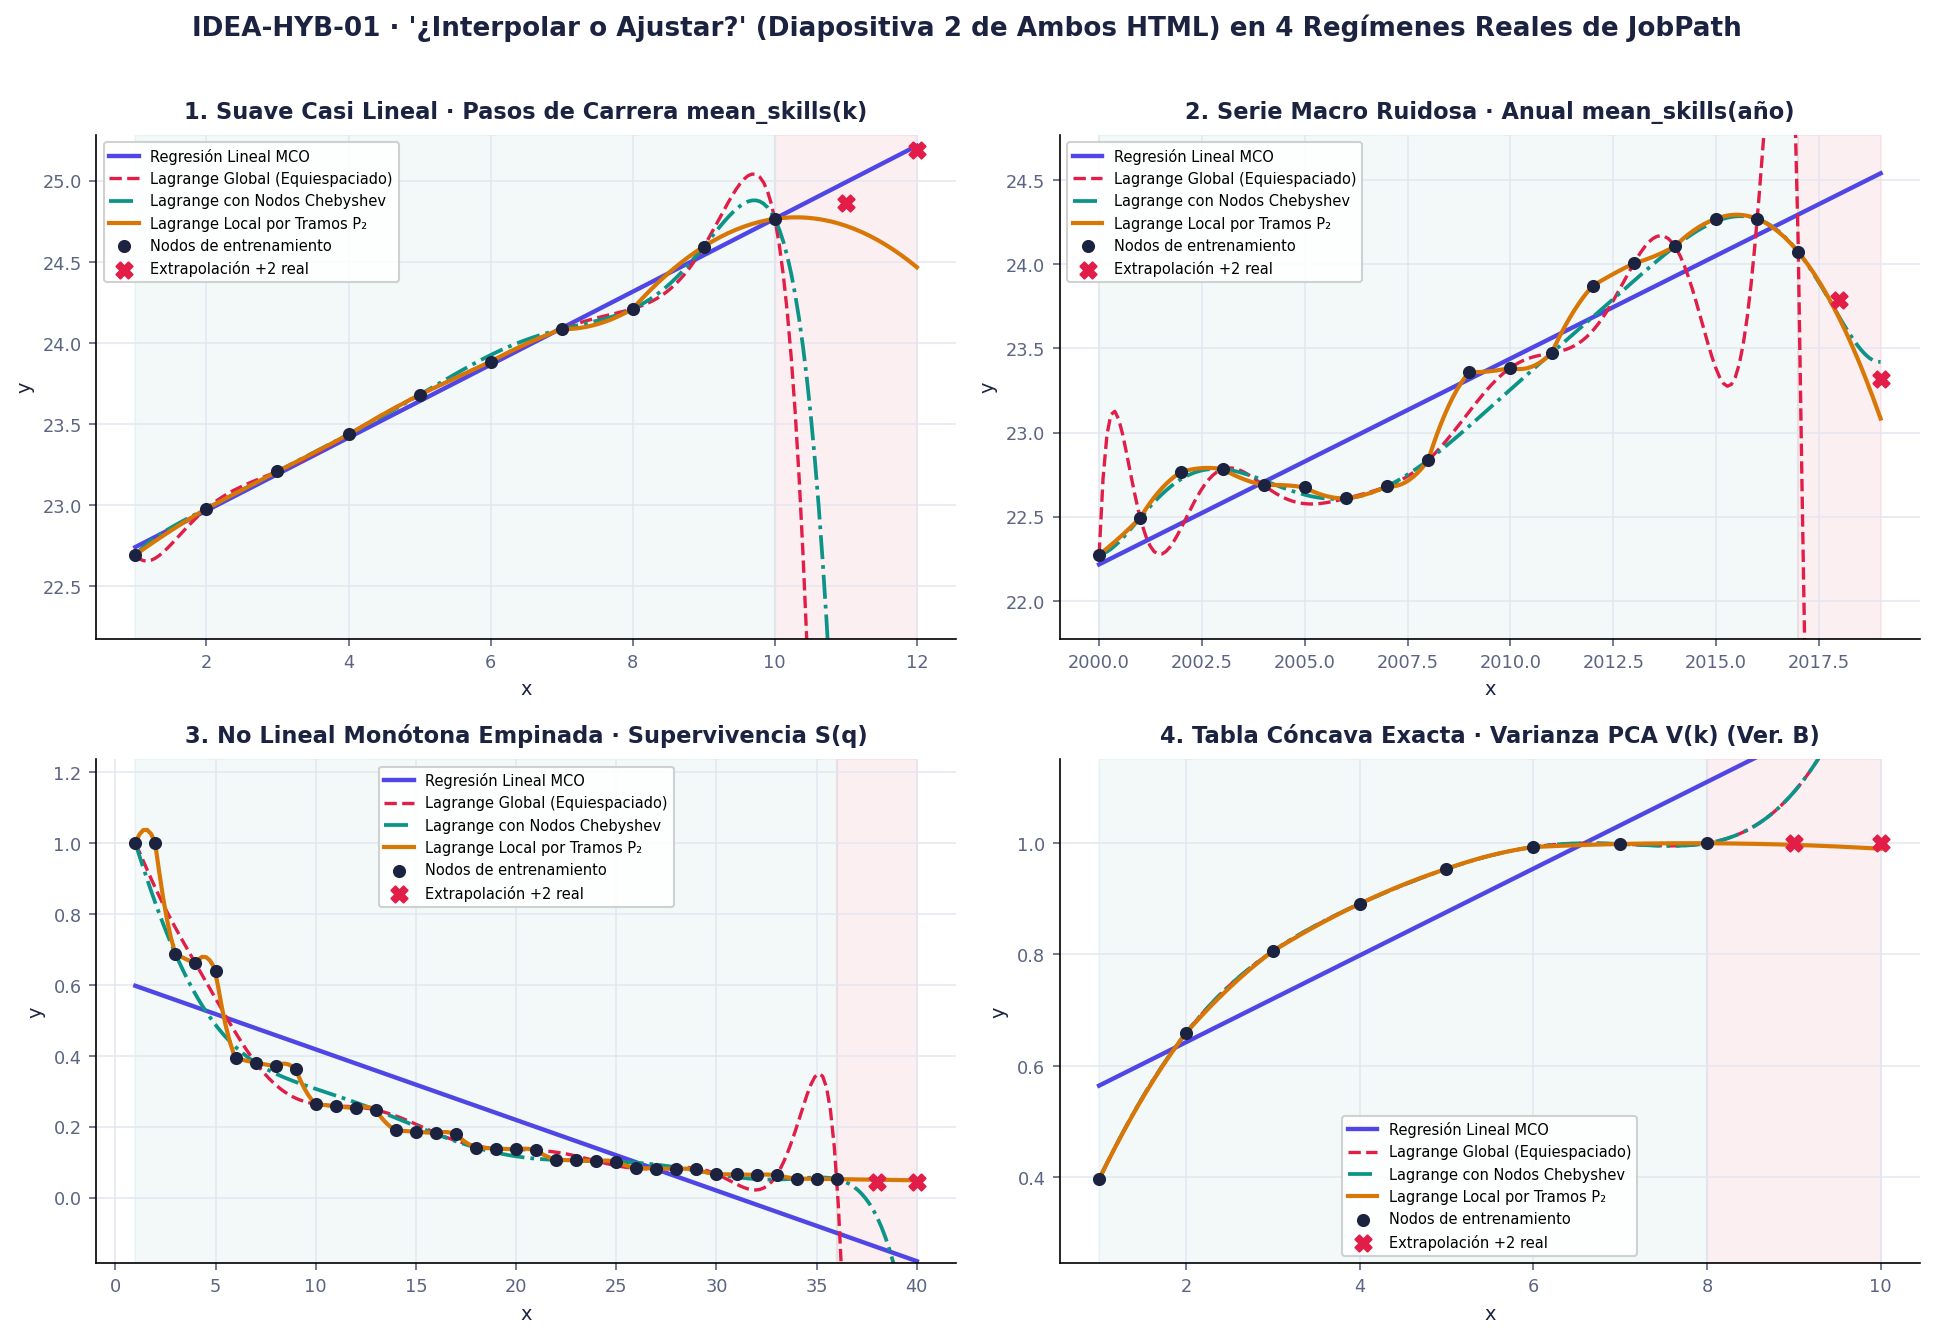

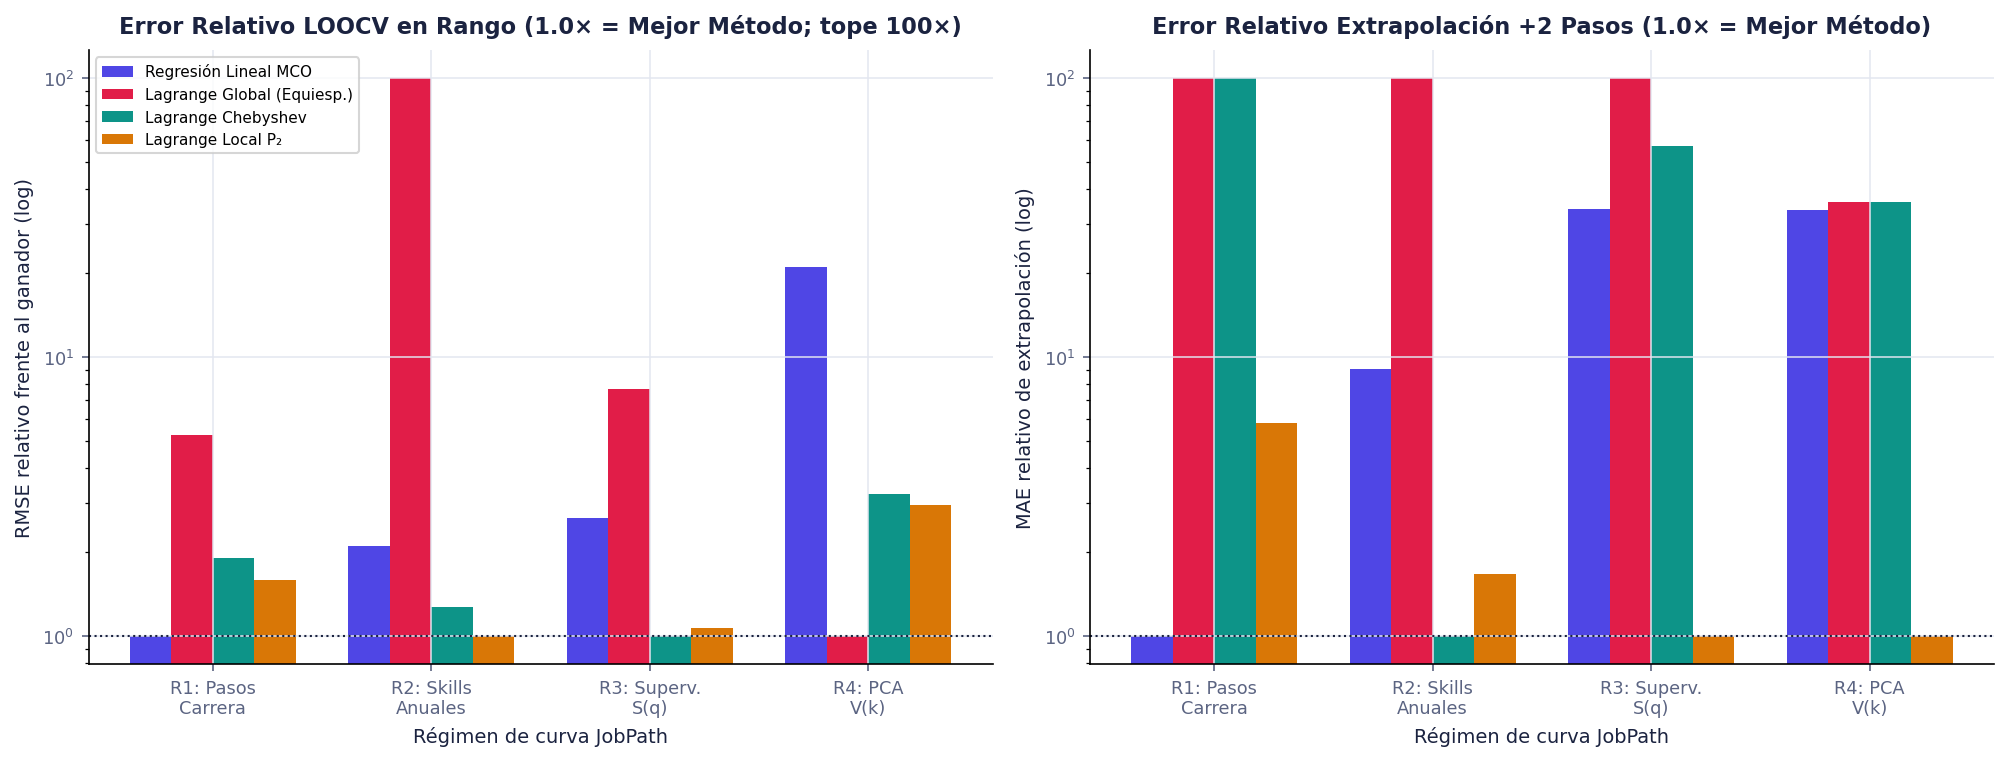

In [3]:
display(Image(filename=str(fdir / "nm10_hyb01_interpolate_vs_fit_four_regimes.png")))
display(Image(filename=str(fdir / "nm11_hyb01_loocv_and_extrapolation_rubric.png")))

## 2. `IDEA-HYB-02` — Pack Automatizado de Verificación en GeoGebra y Tablero de Precisión Numérica

Los 5 estudios canónicos de $n$ pequeño exportan guiones listos para pegar en GeoGebra Classic, verificados programáticamente contra `numpy.polyfit` y `scipy.interpolate` (`< 1e-10`).

,script_file,has_point_list,valid_command_set,family,passed
0,ggb_lg01_survival_p3_milestones.txt,True,True,Lagrange,True
1,ggb_lg02_pca_forward_p3.txt,True,True,Lagrange,True
2,ggb_rl01_career_steps_skills.txt,True,True,OLS,True
3,ggb_rl02_isco10_transferability.txt,True,True,OLS,True
4,ggb_rl04_annual_duration_extrapolation.txt,True,True,OLS,True


# GeoGebra Verification Pack Index (`IDEA-HYB-02`)

Open [GeoGebra Classic](https://www.geogebra.org/classic) and paste the commands from any `.txt` file below into the Algebra Input bar. English command names work in all GeoGebra language locales.

| Case Study | File | Method | Expected Key Output (Python Verified `< 1e-10`) |
|---|---|---|---|
| `IDEA-RL-01` | `ggb_rl01_career_steps_skills.txt` | OLS `FitLine` | `a0 = 22.516043`, `a1 = 0.224971`, `R2 = 0.995498`, `f(12) = 25.215697` |
| `IDEA-RL-02` | `ggb_rl02_isco10_transferability.txt` | OLS `FitLine` | `a0 = 3.448113`, `a1 = 0.432990`, `R2 = 0.280010` |
| `IDEA-RL-04` | `ggb_rl04_annual_duration_extrapolation.txt` | OLS `FitLine` | `a0 = 18.596288`, `a1 = -0.709603`, `R2 = 0.928761`, `f(27) = -0.563000` (negative!) |
| `IDEA-LG-01` | `ggb_lg01_survival_p3_milestones.txt` | Lagrange `P3` vs `Polynomial(P)` | `P3(12) = 0.206491` (true `S(12) = 0.251949`) |
| `IDEA-LG-02` | `ggb_lg02_pca_forward_p3.txt` | Lagrange `P3` vs `Polynomial(P)` | `P3(4) = 0.877777` (true `V(4) = 0.877604`) |


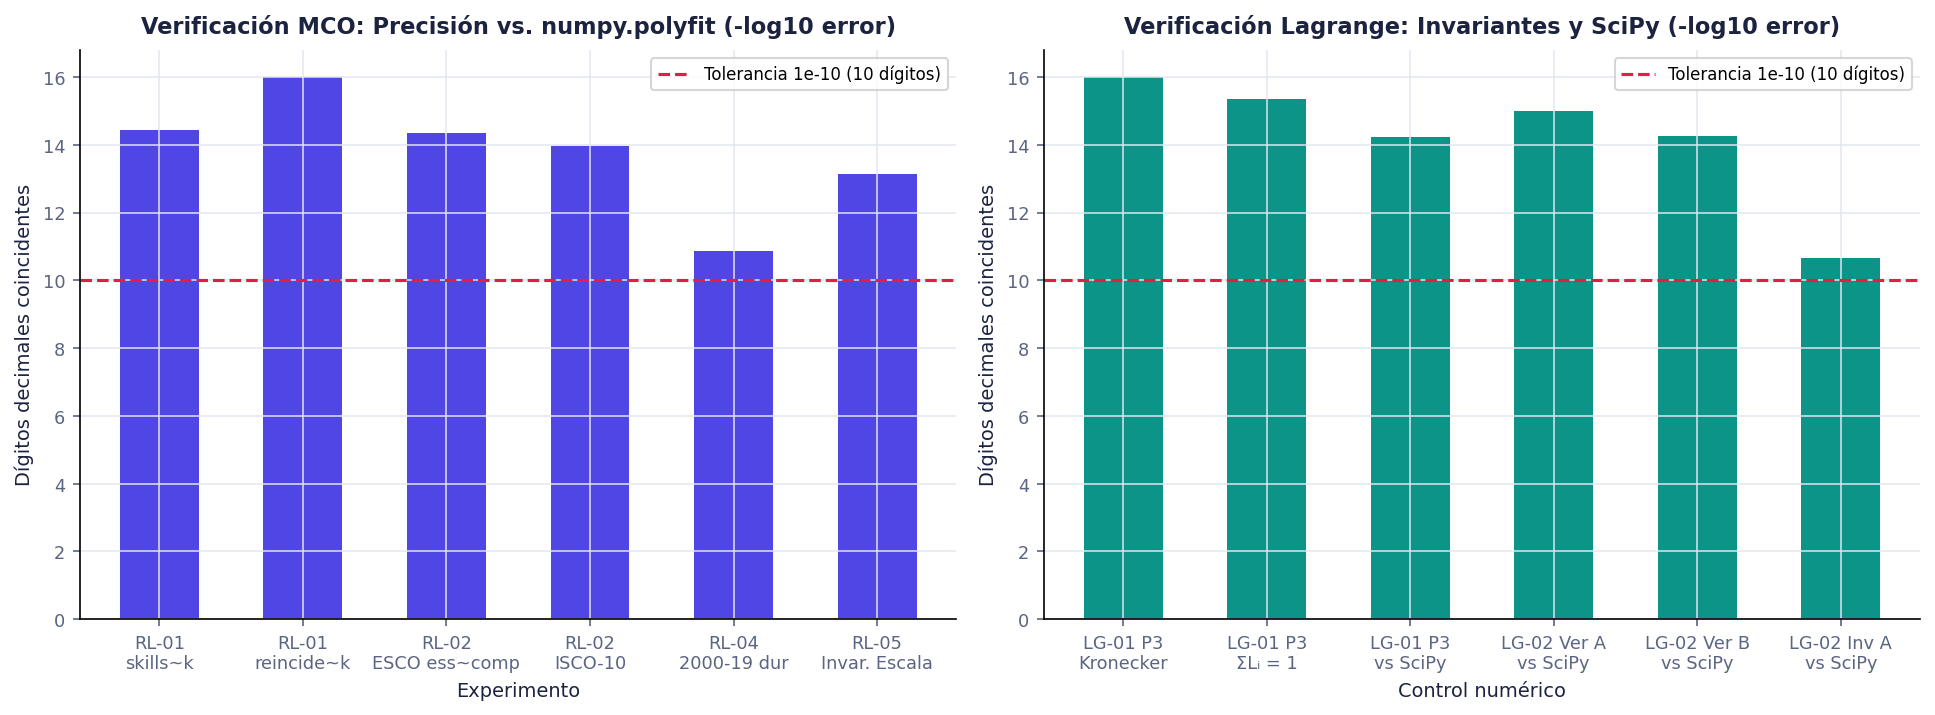

In [4]:
ggb_audit = validate_geogebra_scripts(gdir)
display(ggb_audit)
assert bool(ggb_audit["passed"].all()), "¡Falló la validación de scripts GeoGebra!"

display(Markdown((gdir / "geogebra_verification_index.md").read_text(encoding="utf-8")))
display(Image(filename=str(fdir / "nm12_hyb02_verification_summary_dashboard.png")))

## 3. Compuerta Final de Gobernanza: Inmutabilidad SHA-256 de `data/`, Manifiesto de Figuras y Cumplimiento de Redacción

In [5]:
sha_df = pd.read_csv(tdir / "sha256_input_integrity.csv")
fig_df = verify_figure_manifest(cfg)
wording_df = audit_wording_compliance([
    cfg.verification_log_path,
    gdir / "geogebra_verification_index.md",
    ROOT / "notebooks" / "refactor" / "8.0_regresion_lineal_minimos_cuadrados.ipynb",
    ROOT / "notebooks" / "refactor" / "8.1_interpolacion_lagrange.ipynb",
])

print("Todos los archivos solo-lectura de data/ intactos (SHA-256):", bool(sha_df["intact"].all()))
print("Todas las 12 figuras aprobadas presentes:                   ", bool(fig_df["exists"].all()))
print("Todas las verificaciones de redacción aprobadas (MR-07/08): ", bool(wording_df["passed"].all()))

display(sha_df[["file_name", "sha256_before", "sha256_after", "intact"]])
display(fig_df)
assert bool(sha_df["intact"].all())
assert bool(fig_df["exists"].all())
assert bool(wording_df["passed"].all())

Todos los archivos solo-lectura de data/ intactos (SHA-256): True
Todas las 12 figuras aprobadas presentes:                    True
Todas las verificaciones de redacción aprobadas (MR-07/08):  True


,file_name,sha256_before,sha256_after,intact
0,JobHop_v2_train.csv,68b7d3686c7580a0…,68b7d3686c7580a0…,True
1,JobHop_v2_test.csv,ed28c2671e00c212…,ed28c2671e00c212…,True
2,JobHop_v2_val.csv,c31236fb3639b411…,c31236fb3639b411…,True
3,greenShareOcc_en_limpio.csv,3cc4c43291437fc8…,3cc4c43291437fc8…,True
4,ISCOGroups_en_limpio.csv,a81ef1362babc924…,a81ef1362babc924…,True
5,occupations_en_limpio.csv,1a6d59c8ae1aed23…,1a6d59c8ae1aed23…,True
6,occupationSkillRelations_en_limpio.csv,e1a46511f0ef4d50…,e1a46511f0ef4d50…,True
7,skills_en_limpio.csv,99f0ed64f643a82d…,99f0ed64f643a82d…,True
8,empleos_limpio.csv,4ee5b956e25e8e7a…,4ee5b956e25e8e7a…,True
9,empleos_limpio_sin_outliers .csv,87d9350e82f27646…,87d9350e82f27646…,True


,figure,exists,size_kb
0,nm01_rl01_career_steps_panel.png,True,254.1
1,nm02_rl01_residual_squares_and_extrapolation.png,True,101.5
2,nm03_rl02_esco_high_vs_low_r2.png,True,450.4
3,nm04_rl02_isco_major_group_slopes.png,True,142.9
4,nm05_rl04_annual_drift_and_censoring_extrapola...,True,151.0
5,nm06_rl05_outlier_strategies_and_scale_invaria...,True,110.5
6,nm07_lg01_survival_milestones_and_weights.png,True,185.8
7,nm08_lg01_runge_phenomenon_vs_chebyshev.png,True,165.3
8,nm09_lg02_pca_forward_and_inverse_lagrange.png,True,130.5
9,nm10_hyb01_interpolate_vs_fit_four_regimes.png,True,313.2
